# 3. Extension : Détection de panneaux dans une scène (avec YOLO)

Jusqu'à présent, notre CNN (Classification) travaillait sur des images parfaitement recadrées. Dans la réalité d'un véhicule autonome, la caméra filme une scène complète. Il nous faut donc un modèle capable de **trouver** le panneau avant de le **lire**.

C'est le rôle de **YOLO (You Only Look Once)**, un modèle de détection d'objets extrêmement rapide.

### Le Pipeline de traitement :
1. **Détection (YOLO)** : Analyse l'image complète et trace une boîte (Bounding Box) autour des objets ressemblant à des panneaux.
2. **Extraction & Prétraitement** : Découpage de la boîte et application de la même normalisation que lors de notre entraînement (48x48 pixels).
3. **Classification (Notre CNN)** : Le CNN prend le relais sur l'image découpée et prédit la classe exacte du panneau.

In [1]:
import cv2
import numpy as np
import keras
import matplotlib.pyplot as plt
from ultralytics import YOLO

from trafficsigns.config import ROOT
from trafficsigns.data.preprocessing import resize_img, normalize
from trafficsigns.utils.compute_parameters import load_mean_std

## 3.1 Chargement des modèles et de la scène
Nous utilisons ici un modèle YOLO standard (`yolov8n.pt`). Comme le précise le sujet, ce modèle généraliste n'est pas un expert en panneaux routiers (il connaît surtout le panneau STOP). Il servira donc de "localisateur" général, et notre CNN fera le travail d'expert.

In [2]:
scene_image_path = ROOT / "data" / "raw" / "test_scene.jpg"
cnn_model_path = ROOT / "models" / "test" / "model.keras"
stats_path = ROOT / "models" / "test" / "norm_stats.npz"

print("Chargement de YOLO...")
yolo_detector = YOLO("yolov8n.pt") 

print("Chargement de notre CNN...")
cnn_classifier = keras.models.load_model(cnn_model_path)
mean, std = load_mean_std(stats_path)

Chargement de YOLO...
Chargement de notre CNN...


## 3.2 Inférence : Le test en conditions réelles
Nous allons passer notre image de test dans la chaîne de traitement complète. Observez comment la Bounding Box est découpée mathématiquement via NumPy avant d'être envoyée au CNN.

YOLO a trouvé 3 objets potentiels.


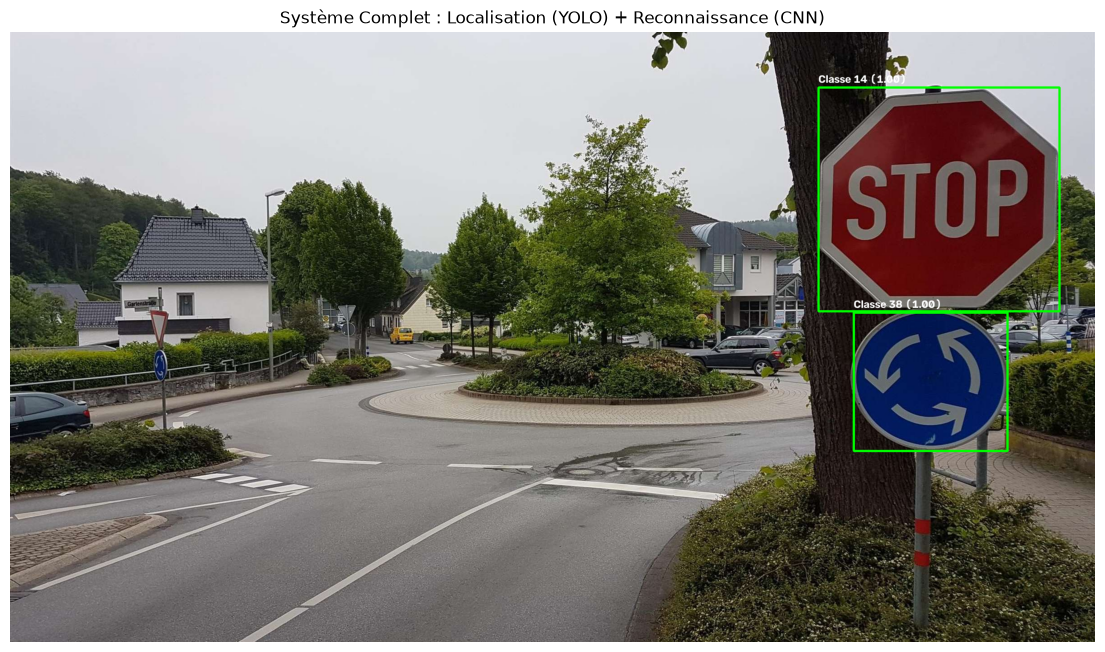

In [3]:
img_bgr = cv2.imread(str(scene_image_path))
img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)
img_result = img_rgb.copy()

results = yolo_detector(img_rgb, verbose=False)
boxes = results[0].boxes
print(f"YOLO a trouvé {len(boxes)} objets potentiels.")

for box in boxes:
    x1, y1, x2, y2 = map(int, box.xyxy[0])
    conf = float(box.conf[0])
    
    if conf < 0.5:
        continue

    cropped_sign = img_rgb[y1:y2, x1:x2]
    if cropped_sign.size == 0:
        continue

    processed_sign = resize_img(cropped_sign, (48, 48))
    processed_sign = normalize(processed_sign, mean=mean, std=std)
    input_tensor = np.expand_dims(processed_sign, axis=0)

    predictions = cnn_classifier.predict(input_tensor, verbose=0)
    predicted_class = np.argmax(predictions[0])
    cnn_confidence = np.max(predictions[0])

    cv2.rectangle(img_result, (x1, y1), (x2, y2), (0, 255, 0), 3)
    label = f"Classe {predicted_class} ({cnn_confidence:.2f})"
    cv2.putText(img_result, label, (x1, max(20, y1 - 10)), 
                cv2.FONT_HERSHEY_SIMPLEX, 0.8, (255, 255, 255), 2)

plt.figure(figsize=(14, 10))
plt.imshow(img_result)
plt.axis('off')
plt.title("Système Complet : Localisation (YOLO) + Reconnaissance (CNN)")
plt.show()

## 3.3 Analyse des résultats
Comme attendu, la communication entre les deux modèles est un succès :
- **Localisation réussie :** YOLO a trouvé la position exacte des deux panneaux dans l'espace.
- **Classification experte :** YOLO (qui ne connaît pas les ronds-points) a cru voir deux panneaux STOP. Notre CNN a corrigé le tir en identifiant le vrai panneau STOP comme **Classe 14 (100% de confiance)** et le panneau de contournement comme **Classe 38 (panneau d'obligation bleu, 100% de confiance)**. 

*Conclusion : Pour passer à l'étape industrielle, il nous suffirait désormais de fine-tuner YOLO (Transfer Learning) sur un dataset spécialisé dans la détection globale de panneaux (pour qu'il ne rate aucun panneau en bord de route), notre CNN se chargeant du reste de l'analyse métier.*